---
## 1. 🔧 Setup & GPU Check

In [8]:
# Cài đặt ultralytics (YOLOv8)
!pip install ultralytics>=8.2.0 -q
!pip install opencv-python-headless -q

In [9]:
import torch
import os
import shutil
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec
from pathlib import Path
from collections import Counter
from PIL import Image
import cv2
import yaml
import pandas as pd
from ultralytics import YOLO

---
## 2. 📦 Data Upload & Extract

**Hướng dẫn:** Nén thư mục `data` thành file `data.zip` rồi upload lên Colab.

Cấu trúc file zip cần có:
```
data/
├── train/
│   ├── images/
│   └── labels/
├── valid/
│   ├── images/
│   └── labels/
├── test/
│   ├── images/
│   └── labels/
└── data.yaml
```

In [10]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/yolov8n


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/yolov8n


In [11]:
!unzip data.zip

Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
  inflating: data/train/labels/c6b20375-fd4e-4331-8f34-10f2a648defb_jpg.rf.8a6188701fdb214463dde2d67f31c4b0.txt  
  inflating: data/train/labels/c6c61cc3-444d-4c3d-b72c-48bf9a58021f_jpg.rf.044af0661aa897f6e503b09573331607.txt  
  inflating: data/train/labels/c6c7c825-742a-412e-9805-c4d2f2084cb0_jpg.rf.575dc38b11ca7b6ea31956fd699180e9.txt  
  inflating: data/train/labels/c6d85594-b2b8-4dad-9ad5-e1b3301547a0_jpg.rf.8f084300a2e9aaa6b505a18e2a665176.txt  
  inflating: data/train/labels/c6eba597-293e-466a-ae01-ec0e364ff094_jpg.rf.574e9eca7511a468fc65d79a2f5bf59e.txt  
  inflating: data/train/labels/c6fb170a-3cea-42a5-867a-bf9b3ff65c9c_jpg.rf.8c98b986e3b851dcffcc7b264f885042.txt  
  inflating: data/train/labels/c6fb6ad5-4bb3-4729-b246-e25c91ca2c85_jpg.rf.35aa9547ee9f2199d0443a74a62ac3ef.txt  
  inflating: data/train/labels/c6ff7adc-b11e-41a6-a381-532df38bfd25_jpg.rf.83abe6915bc5c85249fff936d58b996c.txt  
  inflating: data/train/labels/

In [ ]:
# ============================
# OPTION 2: Mount Google Drive (nếu data đã có trên Drive)
# ============================
# from google.colab import drive
# drive.mount('/content/drive')
# !cp /content/drive/MyDrive/path_to_data.zip /content/
# !unzip -q -o /content/data.zip -d /content/

In [12]:
# Định nghĩa đường dẫn
DATA_DIR = Path("/content/drive/MyDrive/yolov8n/data")
TRAIN_IMG_DIR = DATA_DIR / "train" / "images"
TRAIN_LBL_DIR = DATA_DIR / "train" / "labels"
VALID_IMG_DIR = DATA_DIR / "valid" / "images"
VALID_LBL_DIR = DATA_DIR / "valid" / "labels"
TEST_IMG_DIR  = DATA_DIR / "test"  / "images"
TEST_LBL_DIR  = DATA_DIR / "test"  / "labels"

# Kiểm tra dữ liệu tồn tại
for d in [TRAIN_IMG_DIR, TRAIN_LBL_DIR, VALID_IMG_DIR, VALID_LBL_DIR, TEST_IMG_DIR, TEST_LBL_DIR]:
    count = len(list(d.iterdir())) if d.exists() else 0
    status = "✅" if count > 0 else "❌"
    print(f"{status} {d.relative_to(DATA_DIR)}: {count} files")

✅ train/images: 6218 files
✅ train/labels: 6218 files
✅ valid/images: 1776 files
✅ valid/labels: 1776 files
✅ test/images: 887 files
✅ test/labels: 887 files


---
## 3. 📊 Exploratory Data Analysis (EDA)

In [13]:
# ============================
# 3.1 Thống kê tổng quan
# ============================

ORIGINAL_CLASSES = {0: 'Lights', 1: 'license_plate'}

def parse_labels(label_dir):
    """Parse tất cả label files trong thư mục, trả về danh sách annotations."""
    annotations = []
    label_files = sorted(glob.glob(str(label_dir / "*.txt")))
    for lf in label_files:
        fname = Path(lf).stem
        with open(lf, 'r') as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                cls_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:5])
                annotations.append({
                    'file': fname,
                    'class_id': cls_id,
                    'class_name': ORIGINAL_CLASSES.get(cls_id, f'unknown_{cls_id}'),
                    'x_center': x_center,
                    'y_center': y_center,
                    'width': width,
                    'height': height,
                    'area': width * height
                })
    return pd.DataFrame(annotations)

# Parse annotations cho mỗi split
train_df = parse_labels(TRAIN_LBL_DIR)
valid_df = parse_labels(VALID_LBL_DIR)
test_df  = parse_labels(TEST_LBL_DIR)

print("=" * 60)
print("📊 DATASET OVERVIEW")
print("=" * 60)
for name, df, img_dir in [("Train", train_df, TRAIN_IMG_DIR),
                           ("Valid", valid_df, VALID_IMG_DIR),
                           ("Test",  test_df,  TEST_IMG_DIR)]:
    n_images = len(list(img_dir.glob("*")))
    n_annotations = len(df)
    n_unique_files = df['file'].nunique() if len(df) > 0 else 0
    print(f"\n📁 {name}:")
    print(f"   Images      : {n_images}")
    print(f"   Annotations : {n_annotations}")
    print(f"   Avg ann/img : {n_annotations/max(n_unique_files,1):.2f}")
    if len(df) > 0:
        cls_counts = df['class_name'].value_counts()
        for cls_name, cnt in cls_counts.items():
            print(f"   - {cls_name}: {cnt} ({cnt/n_annotations*100:.1f}%)")

📊 DATASET OVERVIEW

📁 Train:
   Images      : 6218
   Annotations : 6332
   Avg ann/img : 1.02
   - license_plate: 6217 (98.2%)
   - Lights: 115 (1.8%)

📁 Valid:
   Images      : 1776
   Annotations : 1803
   Avg ann/img : 1.02
   - license_plate: 1777 (98.6%)
   - Lights: 26 (1.4%)

📁 Test:
   Images      : 887
   Annotations : 909
   Avg ann/img : 1.02
   - license_plate: 887 (97.6%)
   - Lights: 22 (2.4%)


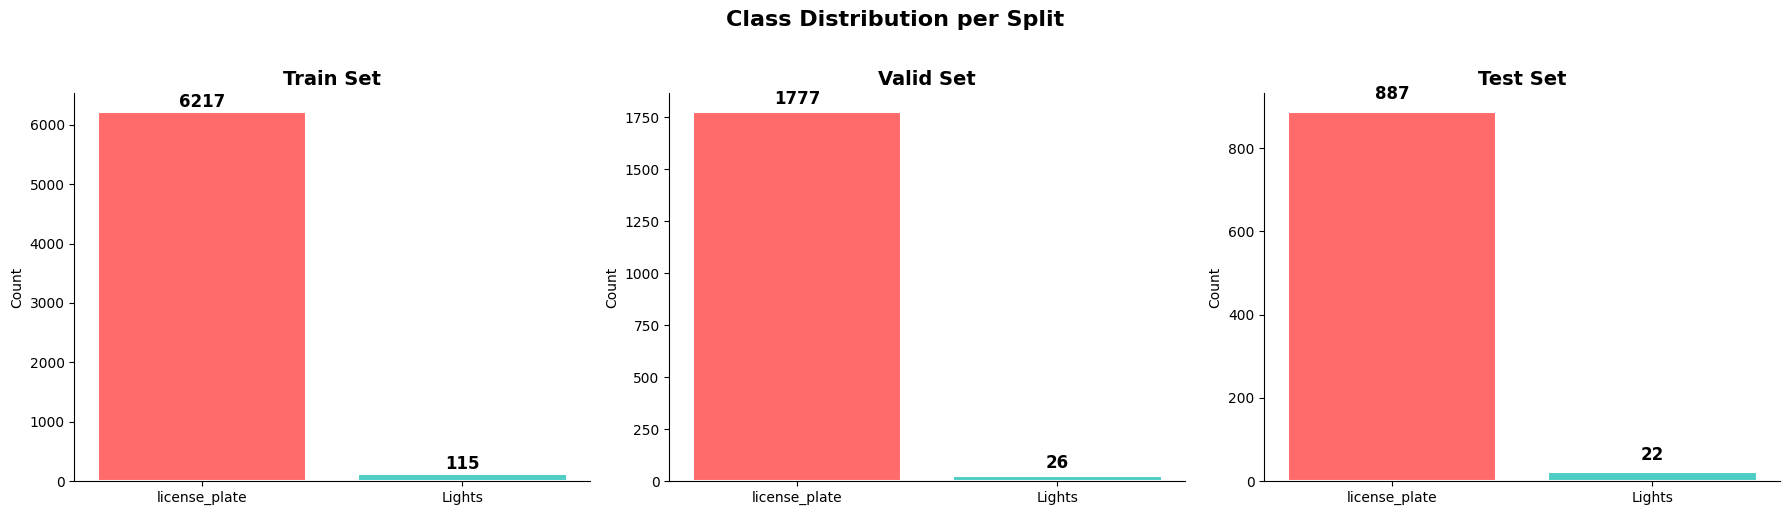

In [14]:
# ============================
# 3.2 Visualize phân bố classes
# ============================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

for ax, (name, df) in zip(axes, [("Train", train_df), ("Valid", valid_df), ("Test", test_df)]):
    if len(df) > 0:
        cls_counts = df['class_name'].value_counts()
        bars = ax.bar(cls_counts.index, cls_counts.values, color=colors[:len(cls_counts)],
                      edgecolor='white', linewidth=1.5)
        for bar, val in zip(bars, cls_counts.values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                    str(val), ha='center', va='bottom', fontweight='bold', fontsize=12)
    ax.set_title(f'{name} Set', fontsize=14, fontweight='bold')
    ax.set_ylabel('Count')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Class Distribution per Split', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

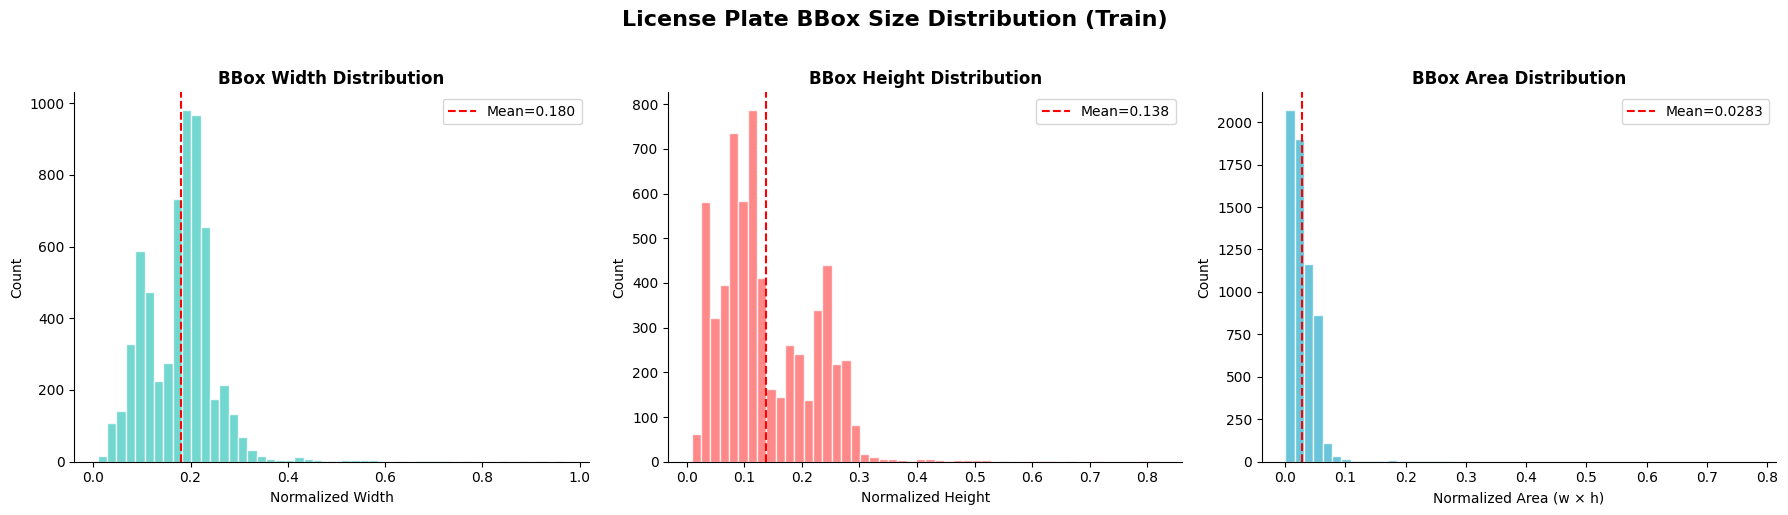


📏 License Plate BBox Statistics (normalized 0-1):
   Width  — Mean: 0.1802, Std: 0.0760, Min: 0.0094, Max: 0.9703
   Height — Mean: 0.1382, Std: 0.0816, Min: 0.0086, Max: 0.8203
   Area   — Mean: 0.028286, Std: 0.030227


In [15]:
# ============================
# 3.3 Phân bố kích thước bounding box
# ============================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chỉ phân tích class license_plate (class_id=1)
lp_train = train_df[train_df['class_id'] == 1]

if len(lp_train) > 0:
    # Width distribution
    axes[0].hist(lp_train['width'], bins=50, color='#4ECDC4', edgecolor='white', alpha=0.8)
    axes[0].set_title('BBox Width Distribution', fontweight='bold')
    axes[0].set_xlabel('Normalized Width')
    axes[0].axvline(lp_train['width'].mean(), color='red', linestyle='--', label=f"Mean={lp_train['width'].mean():.3f}")
    axes[0].legend()

    # Height distribution
    axes[1].hist(lp_train['height'], bins=50, color='#FF6B6B', edgecolor='white', alpha=0.8)
    axes[1].set_title('BBox Height Distribution', fontweight='bold')
    axes[1].set_xlabel('Normalized Height')
    axes[1].axvline(lp_train['height'].mean(), color='red', linestyle='--', label=f"Mean={lp_train['height'].mean():.3f}")
    axes[1].legend()

    # Area distribution
    axes[2].hist(lp_train['area'], bins=50, color='#45B7D1', edgecolor='white', alpha=0.8)
    axes[2].set_title('BBox Area Distribution', fontweight='bold')
    axes[2].set_xlabel('Normalized Area (w × h)')
    axes[2].axvline(lp_train['area'].mean(), color='red', linestyle='--', label=f"Mean={lp_train['area'].mean():.4f}")
    axes[2].legend()

for ax in axes:
    ax.set_ylabel('Count')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('License Plate BBox Size Distribution (Train)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/bbox_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Thống kê chi tiết
if len(lp_train) > 0:
    print("\n📏 License Plate BBox Statistics (normalized 0-1):")
    print(f"   Width  — Mean: {lp_train['width'].mean():.4f}, Std: {lp_train['width'].std():.4f}, Min: {lp_train['width'].min():.4f}, Max: {lp_train['width'].max():.4f}")
    print(f"   Height — Mean: {lp_train['height'].mean():.4f}, Std: {lp_train['height'].std():.4f}, Min: {lp_train['height'].min():.4f}, Max: {lp_train['height'].max():.4f}")
    print(f"   Area   — Mean: {lp_train['area'].mean():.6f}, Std: {lp_train['area'].std():.6f}")

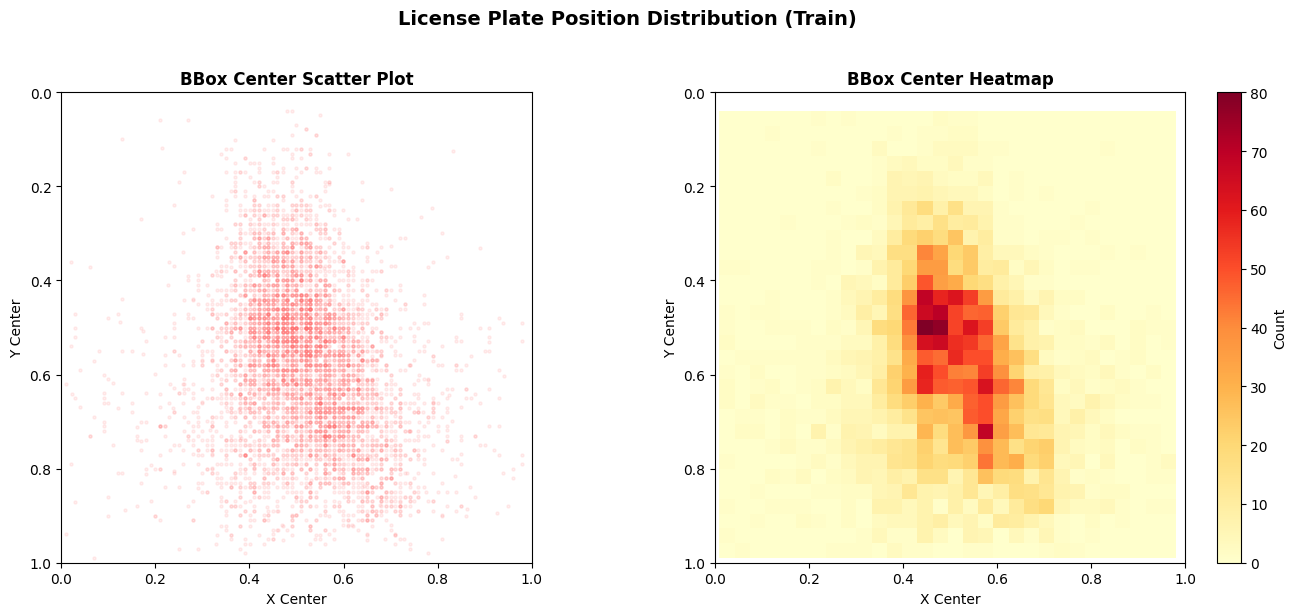

In [16]:
# ============================
# 3.4 Heatmap vị trí center của bounding box
# ============================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

if len(lp_train) > 0:
    # Scatter plot
    axes[0].scatter(lp_train['x_center'], lp_train['y_center'],
                    alpha=0.1, s=5, color='#FF6B6B')
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(1, 0)  # Invert y axis (image coordinates)
    axes[0].set_title('BBox Center Scatter Plot', fontweight='bold')
    axes[0].set_xlabel('X Center')
    axes[0].set_ylabel('Y Center')
    axes[0].set_aspect('equal')

    # 2D Histogram (Heatmap)
    h = axes[1].hist2d(lp_train['x_center'].values, lp_train['y_center'].values,
                       bins=30, cmap='YlOrRd')
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(1, 0)
    axes[1].set_title('BBox Center Heatmap', fontweight='bold')
    axes[1].set_xlabel('X Center')
    axes[1].set_ylabel('Y Center')
    axes[1].set_aspect('equal')
    plt.colorbar(h[3], ax=axes[1], label='Count')

plt.suptitle('License Plate Position Distribution (Train)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/bbox_position_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

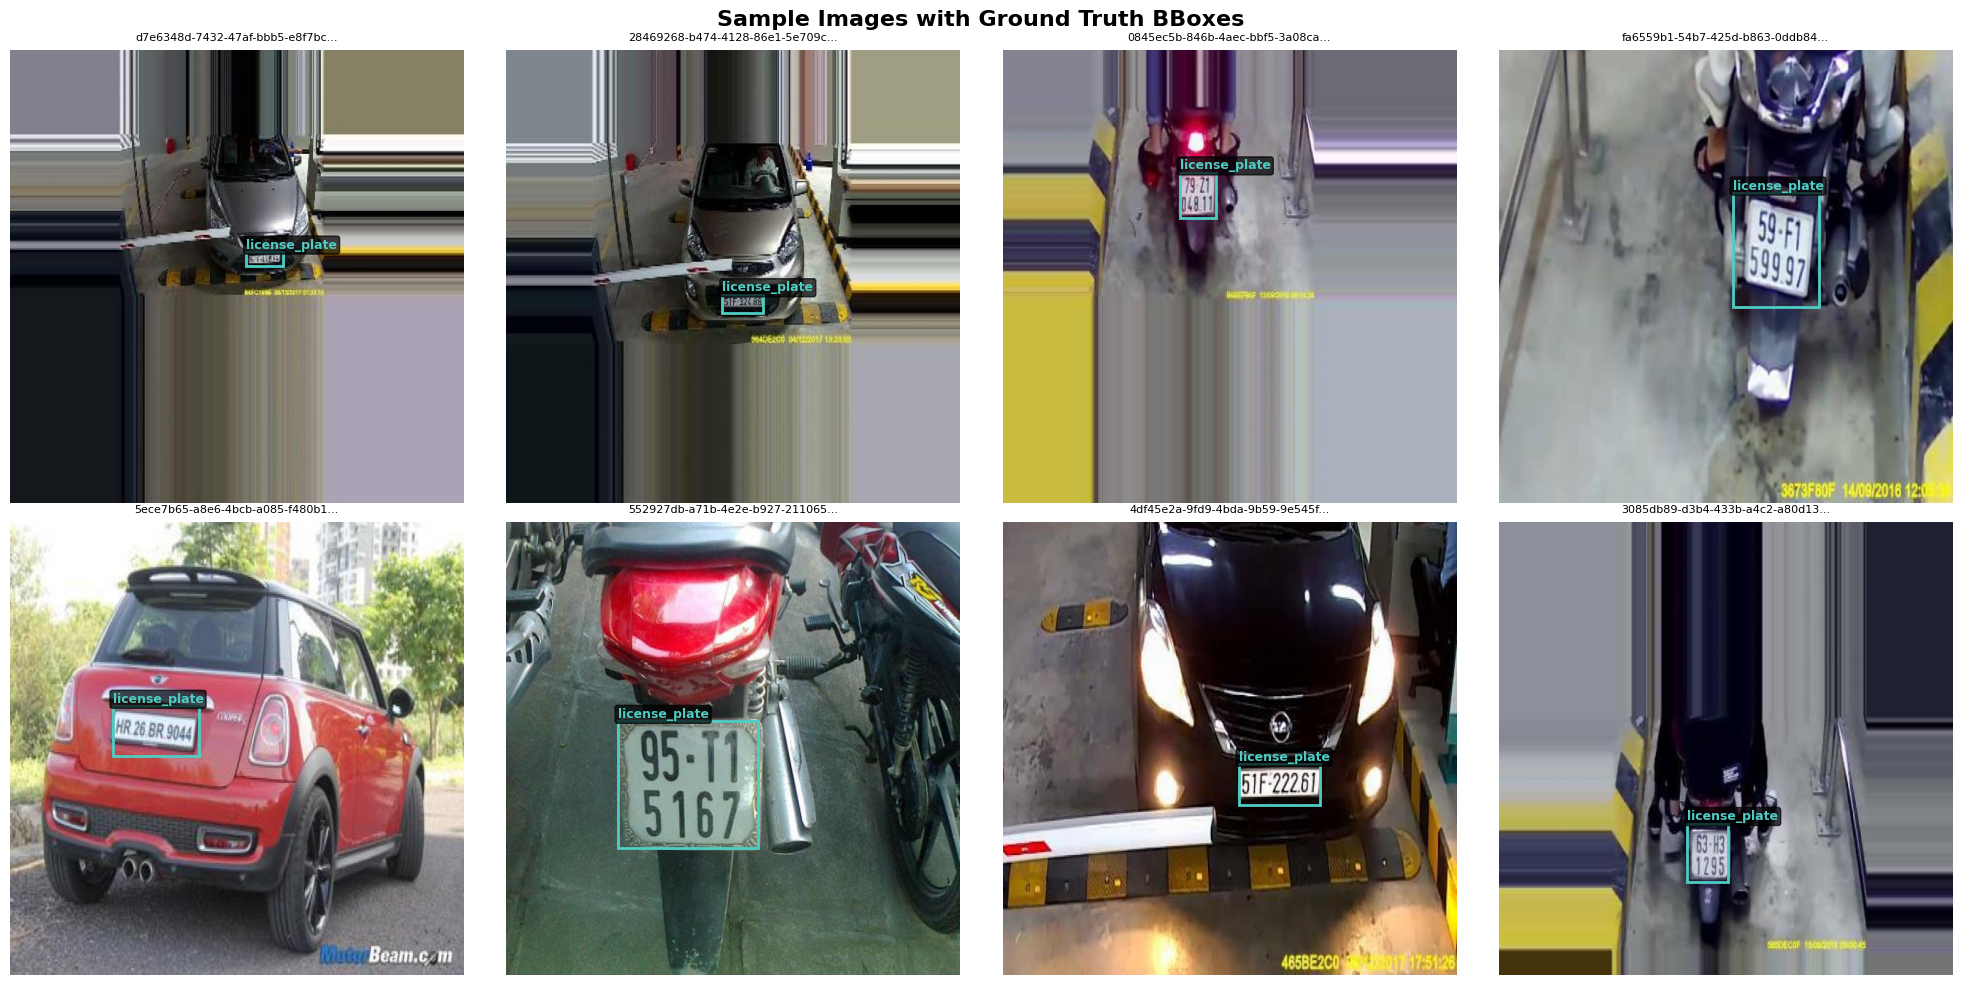

In [17]:
# ============================
# 3.5 Visualize mẫu ảnh với bounding boxes
# ============================

def visualize_samples(img_dir, lbl_dir, class_names, n_samples=8, seed=42):
    """Hiển thị n_samples ảnh ngẫu nhiên với bounding boxes."""
    random.seed(seed)
    img_files = sorted(glob.glob(str(img_dir / "*.jpg")) + glob.glob(str(img_dir / "*.png")))
    samples = random.sample(img_files, min(n_samples, len(img_files)))

    cols = 4
    rows = (len(samples) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
    axes = axes.flatten() if rows > 1 else [axes] if rows == 1 and cols == 1 else axes.flatten()

    bbox_colors = {0: '#FF6B6B', 1: '#4ECDC4'}

    for idx, img_path in enumerate(samples):
        img = Image.open(img_path)
        w, h = img.size
        axes[idx].imshow(img)

        # Load labels
        lbl_path = lbl_dir / (Path(img_path).stem + ".txt")
        if lbl_path.exists():
            with open(lbl_path, 'r') as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls_id = int(parts[0])
                        xc, yc, bw, bh = map(float, parts[1:5])
                        # Convert from YOLO format to pixel coordinates
                        x1 = (xc - bw/2) * w
                        y1 = (yc - bh/2) * h
                        box_w = bw * w
                        box_h = bh * h

                        color = bbox_colors.get(cls_id, '#FFFFFF')
                        rect = patches.Rectangle((x1, y1), box_w, box_h,
                                                  linewidth=2, edgecolor=color,
                                                  facecolor='none')
                        axes[idx].add_patch(rect)
                        axes[idx].text(x1, y1 - 5,
                                       class_names.get(cls_id, str(cls_id)),
                                       color=color, fontsize=9, fontweight='bold',
                                       bbox=dict(boxstyle='round,pad=0.2',
                                                 facecolor='black', alpha=0.7))

        axes[idx].set_title(Path(img_path).name[:30] + '...', fontsize=8)
        axes[idx].axis('off')

    # Hide empty axes
    for idx in range(len(samples), len(axes)):
        axes[idx].axis('off')

    plt.suptitle('Sample Images with Ground Truth BBoxes', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/sample_images.png', dpi=150, bbox_inches='tight')
    plt.show()

visualize_samples(TRAIN_IMG_DIR, TRAIN_LBL_DIR, ORIGINAL_CLASSES, n_samples=8)

📊 Annotations per image — Mean: 1.02, Max: 7, Min: 1


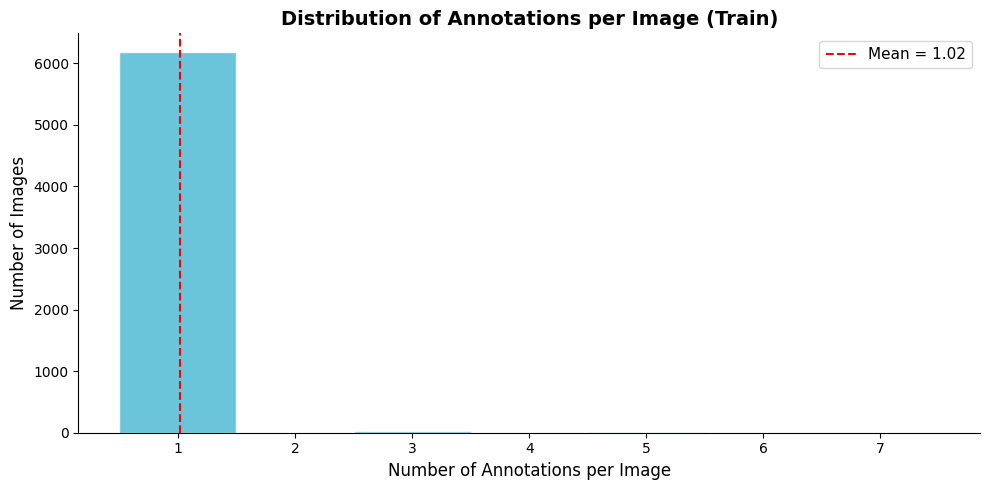

In [18]:
# ============================
# 3.6 Annotations per image histogram
# ============================

fig, ax = plt.subplots(figsize=(10, 5))

if len(train_df) > 0:
    anns_per_img = train_df.groupby('file').size()
    ax.hist(anns_per_img, bins=range(1, anns_per_img.max() + 2), color='#45B7D1',
            edgecolor='white', alpha=0.8, align='left')
    ax.set_xlabel('Number of Annotations per Image', fontsize=12)
    ax.set_ylabel('Number of Images', fontsize=12)
    ax.set_title('Distribution of Annotations per Image (Train)', fontsize=14, fontweight='bold')
    ax.axvline(anns_per_img.mean(), color='red', linestyle='--',
               label=f'Mean = {anns_per_img.mean():.2f}')
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    print(f"📊 Annotations per image — Mean: {anns_per_img.mean():.2f}, Max: {anns_per_img.max()}, Min: {anns_per_img.min()}")

plt.tight_layout()
plt.savefig('/content/anns_per_image.png', dpi=150, bbox_inches='tight')
plt.show()

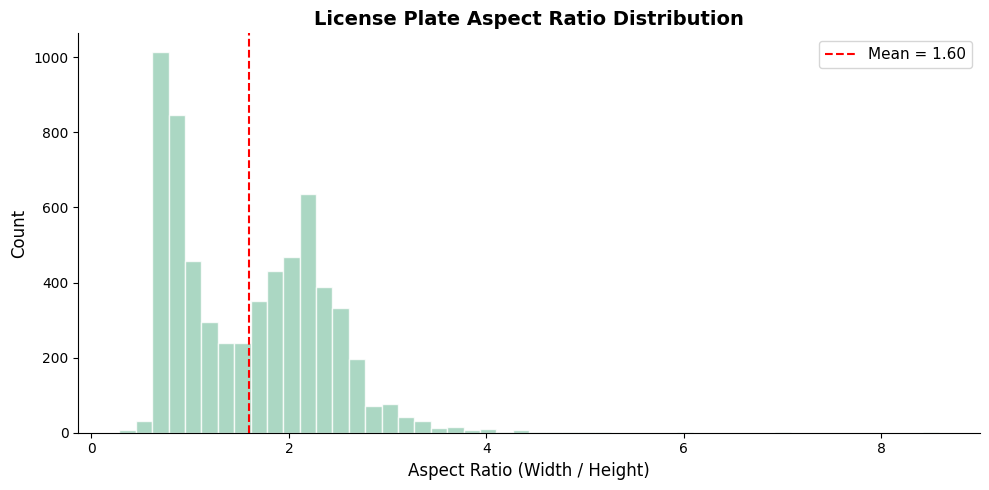

📐 Aspect Ratio — Mean: 1.60, Median: 1.61


In [19]:
# ============================
# 3.7 Aspect ratio analysis
# ============================

if len(lp_train) > 0:
    aspect_ratios = lp_train['width'] / lp_train['height'].clip(lower=1e-6)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(aspect_ratios, bins=50, color='#96CEB4', edgecolor='white', alpha=0.8)
    ax.set_xlabel('Aspect Ratio (Width / Height)', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    ax.set_title('License Plate Aspect Ratio Distribution', fontsize=14, fontweight='bold')
    ax.axvline(aspect_ratios.mean(), color='red', linestyle='--',
               label=f'Mean = {aspect_ratios.mean():.2f}')
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig('/content/aspect_ratio.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"📐 Aspect Ratio — Mean: {aspect_ratios.mean():.2f}, Median: {aspect_ratios.median():.2f}")

---
## 4. 🔄 Data Preparation

Dataset gốc có 2 classes: `Lights` (0) và `license_plate` (1).

Vì chỉ cần detect biển số, ta sẽ:
1. **Lọc** chỉ giữ annotations của class `license_plate` (class_id=1)
2. **Re-map** class_id từ 1 → 0 (vì chỉ còn 1 class duy nhất)
3. Tạo **data.yaml** mới cho YOLOv8

In [20]:
# ============================
# 4.1 Lọc và re-map labels
# ============================

FILTERED_DIR = Path("/content/data_filtered")
SOURCE_CLASS_ID = 1  # license_plate trong dataset gốc
TARGET_CLASS_ID = 0  # class_id mới (chỉ có 1 class)

stats = {'total_files': 0, 'kept_files': 0, 'removed_files': 0,
         'total_annotations': 0, 'kept_annotations': 0}

for split in ['train', 'valid', 'test']:
    src_img_dir = DATA_DIR / split / "images"
    src_lbl_dir = DATA_DIR / split / "labels"
    dst_img_dir = FILTERED_DIR / split / "images"
    dst_lbl_dir = FILTERED_DIR / split / "labels"
    dst_img_dir.mkdir(parents=True, exist_ok=True)
    dst_lbl_dir.mkdir(parents=True, exist_ok=True)

    label_files = sorted(glob.glob(str(src_lbl_dir / "*.txt")))

    for lf in label_files:
        stats['total_files'] += 1
        fname = Path(lf).stem

        with open(lf, 'r') as f:
            lines = f.readlines()

        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            stats['total_annotations'] += 1
            if len(parts) >= 5 and int(parts[0]) == SOURCE_CLASS_ID:
                # Re-map class_id: 1 -> 0
                parts[0] = str(TARGET_CLASS_ID)
                filtered_lines.append(' '.join(parts) + '\n')
                stats['kept_annotations'] += 1

        # Chỉ giữ ảnh có ít nhất 1 annotation license_plate
        if filtered_lines:
            stats['kept_files'] += 1
            # Copy ảnh
            for ext in ['.jpg', '.jpeg', '.png']:
                src_img = src_img_dir / (fname + ext)
                if src_img.exists():
                    shutil.copy2(str(src_img), str(dst_img_dir / src_img.name))
                    break
            # Ghi label mới
            with open(dst_lbl_dir / (fname + ".txt"), 'w') as f:
                f.writelines(filtered_lines)
        else:
            stats['removed_files'] += 1

print("=" * 60)
print("🔄 DATA FILTERING RESULTS")
print("=" * 60)
print(f"Total label files processed : {stats['total_files']}")
print(f"Files kept (has LP)         : {stats['kept_files']}")
print(f"Files removed (no LP)       : {stats['removed_files']}")
print(f"Total annotations           : {stats['total_annotations']}")
print(f"Kept annotations (LP only)  : {stats['kept_annotations']}")
print(f"Removed annotations         : {stats['total_annotations'] - stats['kept_annotations']}")

# Verify
print("\n📁 Filtered dataset:")
for split in ['train', 'valid', 'test']:
    n_img = len(list((FILTERED_DIR / split / "images").glob("*")))
    n_lbl = len(list((FILTERED_DIR / split / "labels").glob("*.txt")))
    print(f"   {split}: {n_img} images, {n_lbl} labels")

🔄 DATA FILTERING RESULTS
Total label files processed : 8881
Files kept (has LP)         : 8879
Files removed (no LP)       : 2
Total annotations           : 9044
Kept annotations (LP only)  : 8881
Removed annotations         : 163

📁 Filtered dataset:
   train: 6216 images, 6216 labels
   valid: 1776 images, 1776 labels
   test: 887 images, 887 labels


In [21]:
# ============================
# 4.2 Tạo data.yaml cho YOLOv8
# ============================

data_yaml = {
    'path': str(FILTERED_DIR),
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': 1,
    'names': ['license_plate']
}

DATA_YAML_PATH = FILTERED_DIR / 'data.yaml'
with open(DATA_YAML_PATH, 'w') as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

print("✅ data.yaml created:")
print("─" * 40)
with open(DATA_YAML_PATH, 'r') as f:
    print(f.read())

✅ data.yaml created:
────────────────────────────────────────
path: /content/data_filtered
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- license_plate



In [22]:
# ============================
# 4.3 Verify filtered labels
# ============================

# Kiểm tra vài label file đã lọc
sample_labels = sorted(glob.glob(str(FILTERED_DIR / "train" / "labels" / "*.txt")))[:5]
print("🔍 Sample filtered labels:")
for lf in sample_labels:
    with open(lf, 'r') as f:
        content = f.read().strip()
    print(f"   {Path(lf).name[:40]}... → {content}")

# Verify all labels only contain class 0
all_filtered_labels = glob.glob(str(FILTERED_DIR / "**" / "labels" / "*.txt"), recursive=True)
class_ids_found = set()
for lf in all_filtered_labels:
    with open(lf, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                class_ids_found.add(int(parts[0]))

print(f"\n✅ Unique class IDs in filtered dataset: {class_ids_found}")
assert class_ids_found == {0}, f"❌ Expected only class 0, found: {class_ids_found}"

🔍 Sample filtered labels:
   0000aa59-162e-4b76-af3f-9ebcd20325e0_jpg... → 0 0.759375 0.6796875 0.16953125 0.171875
   000a9942-fb05-4e81-84fc-4f009214cd2d_jpg... → 0 0.55 0.63046875 0.209375 0.2703125
   000b6d84-5cd3-4ff5-878e-d522257ce7a9_jpg... → 0 0.5203125 0.5 0.06953125 0.09921875
   0013bd30-11e1-4312-ae91-98e3c24fa689_jpg... → 0 0.59921875 0.46015625 0.09921875 0.0296875
   001659b9-4e0f-428a-a090-6f1d4c442860_jpg... → 0 0.36953125 0.15 0.25 0.11875

✅ Unique class IDs in filtered dataset: {0}


---
## 5. 🚀 Training YOLOv8n

### Hyperparameters tối ưu cho License Plate Detection:
- **Model**: YOLOv8n (Nano — nhẹ nhất, nhanh nhất)
- **Image size**: 640 (match với dữ liệu đã resize)
- **Batch size**: 16 (phù hợp T4 GPU 16GB)
- **Epochs**: 100 (early stopping sẽ dừng sớm nếu không cải thiện)
- **Optimizer**: SGD (ổn định hơn Adam cho YOLO)
- **Augmentation**: Mặc định của YOLOv8 (mosaic, flip, hsv, etc.)

In [23]:
# ============================
# 5.1 Khởi tạo model
# ============================

# Load YOLOv8n pretrained on COCO
model = YOLO('yolov8n.pt')

print("✅ YOLOv8n model loaded!")
print(f"   Model type   : {model.type}")
print(f"   Task         : {model.task}")

✅ YOLOv8n model loaded!
   Model type   : <bound method Module.type of YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn):

In [24]:
# ============================
# 5.2 Training
# ============================

PROJECT_NAME = "license_plate_yolov8n"
RUN_NAME = "train_v1"

results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=100,
    imgsz=640,
    batch=16,

    # Optimizer
    optimizer='SGD',
    lr0=0.01,           # Learning rate ban đầu
    lrf=0.01,           # Final learning rate (lr0 * lrf)
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,

    # Augmentation (tối ưu cho license plate)
    hsv_h=0.015,        # Hue augmentation
    hsv_s=0.7,          # Saturation augmentation
    hsv_v=0.4,          # Value augmentation
    degrees=5.0,        # Rotation (nhẹ vì biển số thường ngang)
    translate=0.1,      # Translation
    scale=0.5,          # Scale augmentation
    shear=2.0,          # Shear
    flipud=0.0,         # Không flip dọc (biển số không bao giờ lộn ngược)
    fliplr=0.5,         # Flip ngang
    mosaic=1.0,         # Mosaic augmentation
    mixup=0.0,          # Không dùng mixup

    # Callbacks & saving
    patience=20,        # Early stopping patience
    save=True,
    save_period=10,     # Save checkpoint mỗi 10 epochs
    val=True,
    plots=True,

    # Output
    project=f'/content/{PROJECT_NAME}',
    name=RUN_NAME,
    exist_ok=True,

    # Performance
    workers=2,
    device=0,           # GPU 0
    amp=True,           # Automatic Mixed Precision (tăng tốc training)

    verbose=True,
)

print("\n" + "=" * 60)
print("🎉 TRAINING COMPLETED!")
print("=" * 60)

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_filtered/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_v1, nbs=64, nms=False,

---
## 6. 📈 Loss & Metrics Visualization

In [25]:
# ============================
# 6.1 Load training results từ CSV
# ============================

TRAIN_DIR = Path(f'/content/{PROJECT_NAME}/{RUN_NAME}')
results_csv = TRAIN_DIR / 'results.csv'

if results_csv.exists():
    df_results = pd.read_csv(results_csv)
    df_results.columns = df_results.columns.str.strip()  # Remove whitespace from column names
    print("📊 Available metrics:")
    for col in df_results.columns:
        print(f"   - {col}")
else:
    print("❌ results.csv not found!")

📊 Available metrics:
   - epoch
   - time
   - train/box_loss
   - train/cls_loss
   - train/dfl_loss
   - metrics/precision(B)
   - metrics/recall(B)
   - metrics/mAP50(B)
   - metrics/mAP50-95(B)
   - val/box_loss
   - val/cls_loss
   - val/dfl_loss
   - lr/pg0
   - lr/pg1
   - lr/pg2


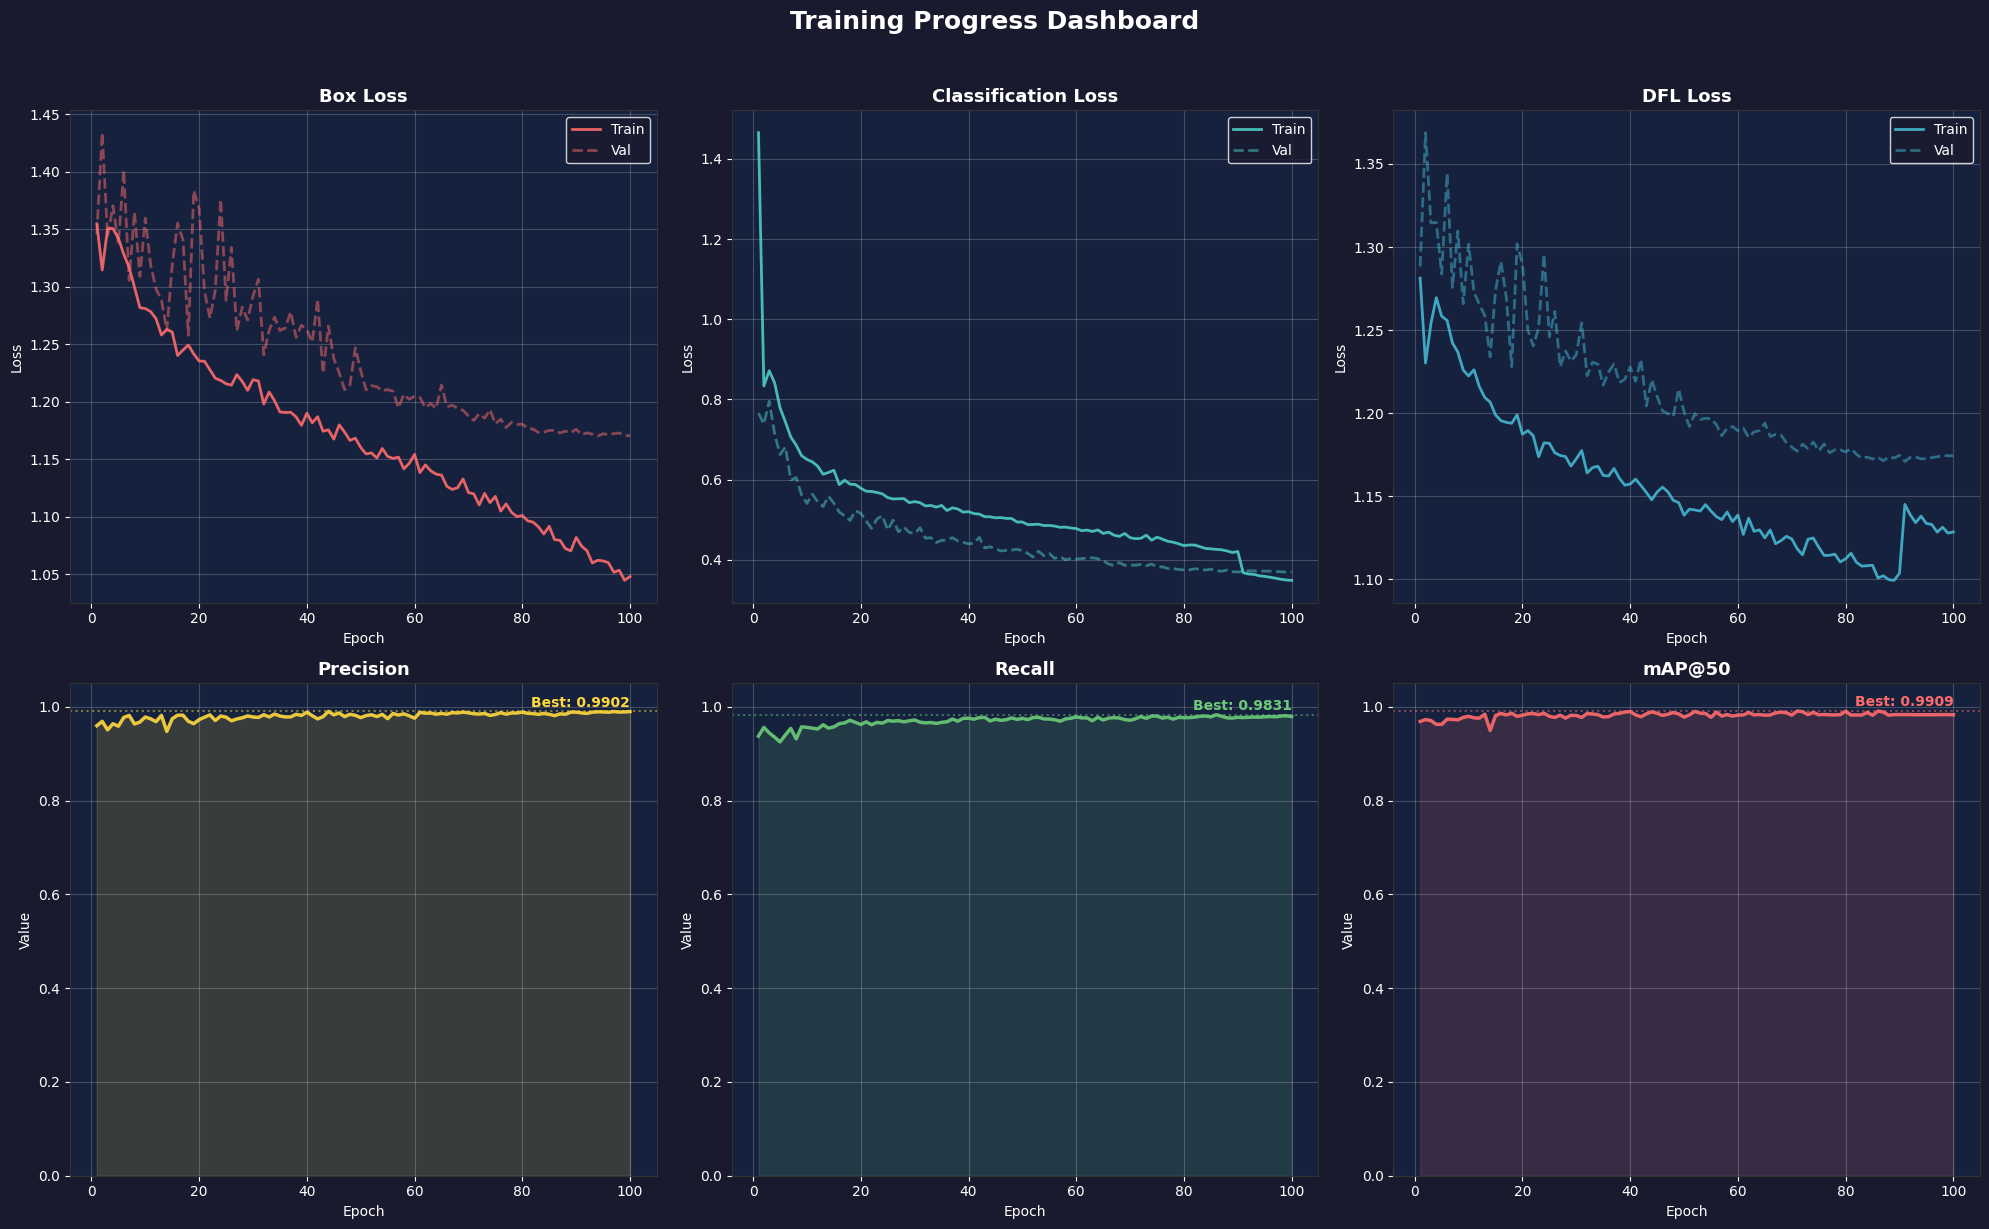

In [26]:
# ============================
# 6.2 Loss Curves
# ============================

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.patch.set_facecolor('#1a1a2e')

loss_metrics = [
    ('train/box_loss', 'val/box_loss', 'Box Loss', '#FF6B6B', '#FF6B6B'),
    ('train/cls_loss', 'val/cls_loss', 'Classification Loss', '#4ECDC4', '#4ECDC4'),
    ('train/dfl_loss', 'val/dfl_loss', 'DFL Loss', '#45B7D1', '#45B7D1'),
]

for idx, (train_col, val_col, title, train_color, val_color) in enumerate(loss_metrics):
    ax = axes[0, idx]
    ax.set_facecolor('#16213e')

    if train_col in df_results.columns:
        ax.plot(df_results['epoch'], df_results[train_col],
                color=train_color, linewidth=2, alpha=0.9, label='Train')
    if val_col in df_results.columns:
        ax.plot(df_results['epoch'], df_results[val_col],
                color=val_color, linewidth=2, alpha=0.5, linestyle='--', label='Val')

    ax.set_title(title, fontsize=13, fontweight='bold', color='white')
    ax.set_xlabel('Epoch', color='white')
    ax.set_ylabel('Loss', color='white')
    ax.legend(fontsize=10, facecolor='#1a1a2e', edgecolor='white', labelcolor='white')
    ax.tick_params(colors='white')
    ax.grid(True, alpha=0.2, color='white')
    for spine in ax.spines.values():
        spine.set_color('#333')

# Metrics
metric_plots = [
    ('metrics/precision(B)', 'Precision', '#FFD93D'),
    ('metrics/recall(B)', 'Recall', '#6BCB77'),
    ('metrics/mAP50(B)', 'mAP@50', '#FF6B6B'),
]

for idx, (col, title, color) in enumerate(metric_plots):
    ax = axes[1, idx]
    ax.set_facecolor('#16213e')

    if col in df_results.columns:
        ax.plot(df_results['epoch'], df_results[col],
                color=color, linewidth=2.5, alpha=0.9)
        ax.fill_between(df_results['epoch'], df_results[col],
                        alpha=0.15, color=color)
        # Annotate final value
        final_val = df_results[col].iloc[-1]
        best_val = df_results[col].max()
        ax.axhline(y=best_val, color=color, linestyle=':', alpha=0.5)
        ax.text(df_results['epoch'].iloc[-1], best_val + 0.01,
                f'Best: {best_val:.4f}', color=color, fontsize=10, fontweight='bold',
                ha='right')

    ax.set_title(title, fontsize=13, fontweight='bold', color='white')
    ax.set_xlabel('Epoch', color='white')
    ax.set_ylabel('Value', color='white')
    ax.set_ylim(0, 1.05)
    ax.tick_params(colors='white')
    ax.grid(True, alpha=0.2, color='white')
    for spine in ax.spines.values():
        spine.set_color('#333')

plt.suptitle('Training Progress Dashboard', fontsize=18, fontweight='bold',
             color='white', y=1.02)
plt.tight_layout()
plt.savefig('/content/training_dashboard.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

🏆 Best mAP@50    : 0.9909 (epoch 71)
🏆 Best mAP@50-95 : 0.6722 (epoch 84)


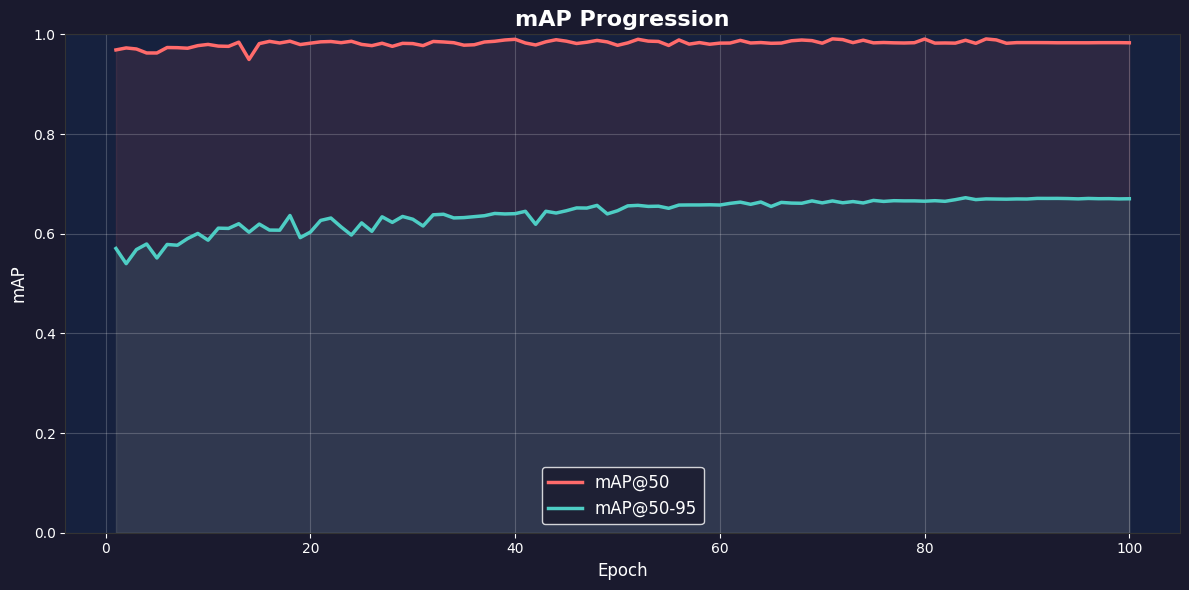

In [27]:
# ============================
# 6.3 mAP50 vs mAP50-95 comparison
# ============================

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#16213e')

if 'metrics/mAP50(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/mAP50(B)'],
            color='#FF6B6B', linewidth=2.5, label='mAP@50', marker='', markersize=3)
    ax.fill_between(df_results['epoch'], df_results['metrics/mAP50(B)'],
                    alpha=0.1, color='#FF6B6B')

if 'metrics/mAP50-95(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/mAP50-95(B)'],
            color='#4ECDC4', linewidth=2.5, label='mAP@50-95', marker='', markersize=3)
    ax.fill_between(df_results['epoch'], df_results['metrics/mAP50-95(B)'],
                    alpha=0.1, color='#4ECDC4')

ax.set_title('mAP Progression', fontsize=16, fontweight='bold', color='white')
ax.set_xlabel('Epoch', fontsize=12, color='white')
ax.set_ylabel('mAP', fontsize=12, color='white')
ax.set_ylim(0, 1.0)
ax.legend(fontsize=12, facecolor='#1a1a2e', edgecolor='white', labelcolor='white')
ax.tick_params(colors='white')
ax.grid(True, alpha=0.2, color='white')
for spine in ax.spines.values():
    spine.set_color('#333')

# Print best values
if 'metrics/mAP50(B)' in df_results.columns:
    best_map50 = df_results['metrics/mAP50(B)'].max()
    best_map50_epoch = df_results.loc[df_results['metrics/mAP50(B)'].idxmax(), 'epoch']
    print(f"🏆 Best mAP@50    : {best_map50:.4f} (epoch {int(best_map50_epoch)})")

if 'metrics/mAP50-95(B)' in df_results.columns:
    best_map5095 = df_results['metrics/mAP50-95(B)'].max()
    best_map5095_epoch = df_results.loc[df_results['metrics/mAP50-95(B)'].idxmax(), 'epoch']
    print(f"🏆 Best mAP@50-95 : {best_map5095:.4f} (epoch {int(best_map5095_epoch)})")

plt.tight_layout()
plt.savefig('/content/map_progression.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

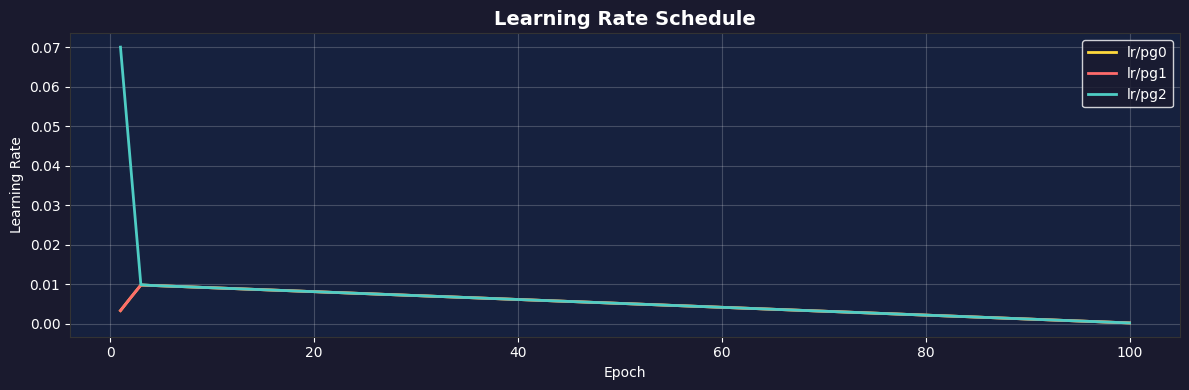

In [28]:
# ============================
# 6.4 Learning Rate Schedule
# ============================

lr_cols = [c for c in df_results.columns if 'lr' in c.lower()]

if lr_cols:
    fig, ax = plt.subplots(figsize=(12, 4))
    fig.patch.set_facecolor('#1a1a2e')
    ax.set_facecolor('#16213e')

    colors_lr = ['#FFD93D', '#FF6B6B', '#4ECDC4']
    for col, color in zip(lr_cols, colors_lr):
        ax.plot(df_results['epoch'], df_results[col], color=color,
                linewidth=2, label=col)

    ax.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold', color='white')
    ax.set_xlabel('Epoch', color='white')
    ax.set_ylabel('Learning Rate', color='white')
    ax.legend(fontsize=10, facecolor='#1a1a2e', edgecolor='white', labelcolor='white')
    ax.tick_params(colors='white')
    ax.grid(True, alpha=0.2, color='white')
    for spine in ax.spines.values():
        spine.set_color('#333')
    plt.tight_layout()
    plt.show()

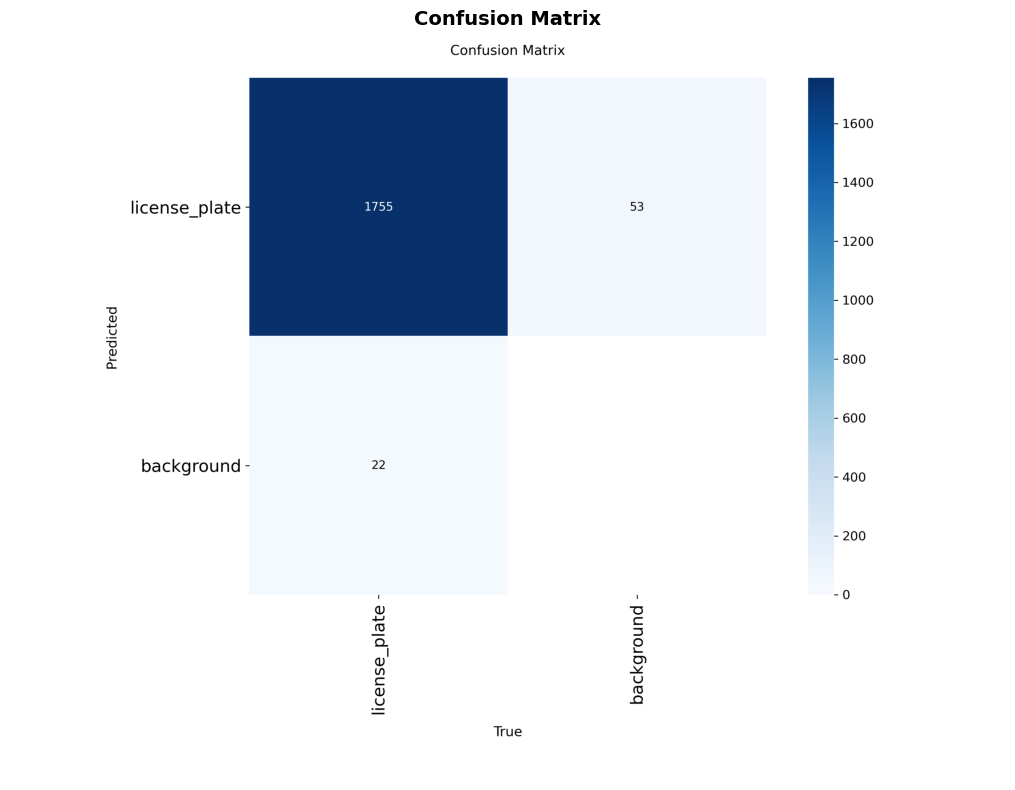

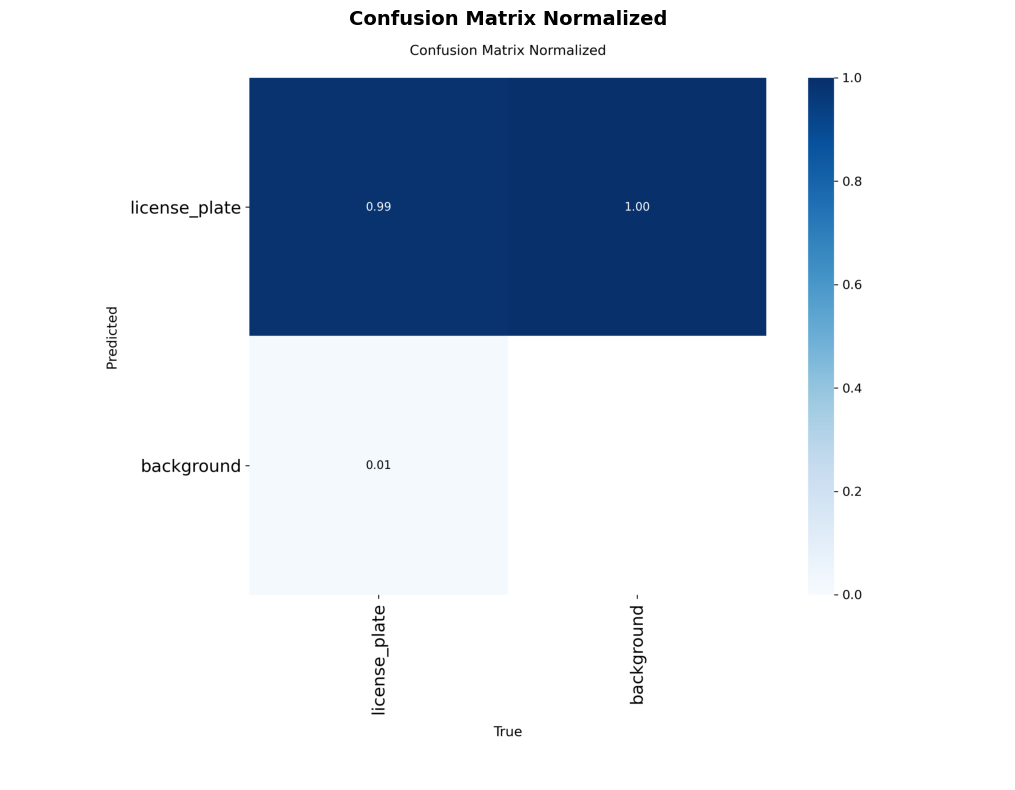

⚠️  F1_curve.png not found
⚠️  P_curve.png not found
⚠️  R_curve.png not found
⚠️  PR_curve.png not found


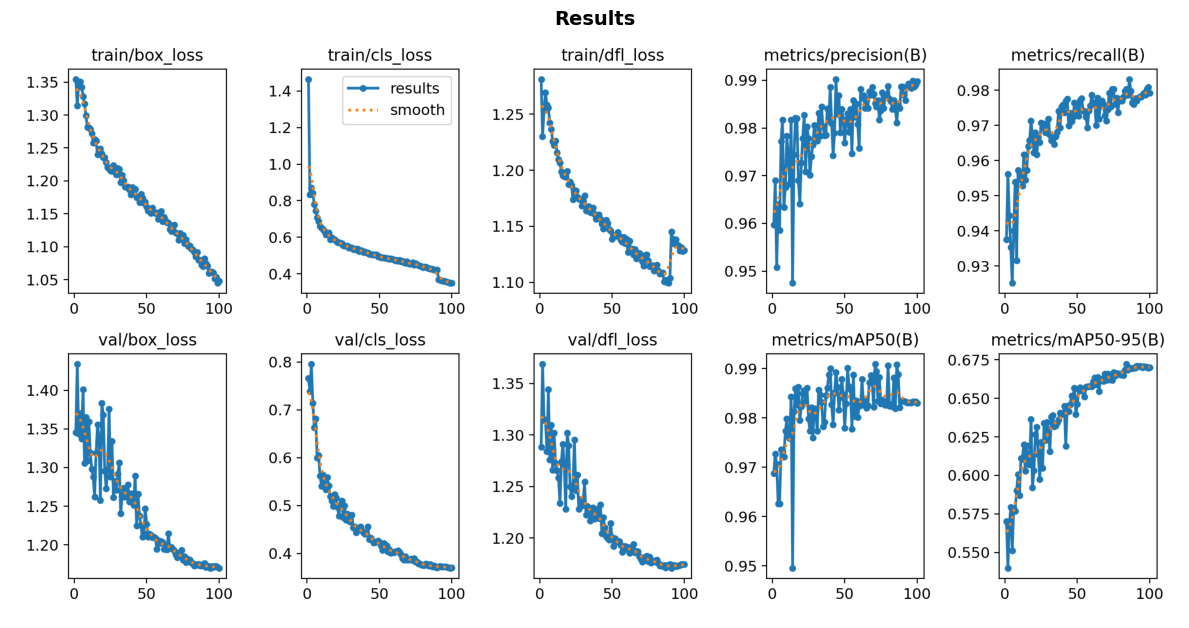

In [29]:
# ============================
# 6.5 Hiển thị các plots tự động tạo bởi YOLOv8
# ============================

auto_plots = [
    'confusion_matrix.png',
    'confusion_matrix_normalized.png',
    'F1_curve.png',
    'P_curve.png',
    'R_curve.png',
    'PR_curve.png',
    'results.png',
]

for plot_name in auto_plots:
    plot_path = TRAIN_DIR / plot_name
    if plot_path.exists():
        img = Image.open(plot_path)
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.imshow(img)
        ax.set_title(plot_name.replace('.png', '').replace('_', ' ').title(),
                     fontsize=14, fontweight='bold')
        ax.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print(f"⚠️  {plot_name} not found")

---
## 7. 🎯 Evaluation on Test Set

In [30]:
# ============================
# 7.1 Load best model và evaluate
# ============================

BEST_MODEL_PATH = TRAIN_DIR / 'weights' / 'best.pt'
print(f"📦 Loading best model from: {BEST_MODEL_PATH}")

best_model = YOLO(str(BEST_MODEL_PATH))

# Evaluate trên test set
test_results = best_model.val(
    data=str(DATA_YAML_PATH),
    split='test',
    imgsz=640,
    batch=16,
    conf=0.25,
    iou=0.6,
    device=0,
    plots=True,
    save_json=False,
    verbose=True,
)

📦 Loading best model from: /content/license_plate_yolov8n/train_v1/weights/best.pt
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1345.9±346.9 MB/s, size: 52.0 KB)
val: Scanning /content/data_filtered/test/labels... 887 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 887/887 2.1Kit/s 0.4s
val: New cache created: /content/data_filtered/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 3.6it/s 15.8s
                   all        887        887       0.98      0.971      0.982      0.668
Speed: 2.8ms preprocess, 4.7ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/drive/MyDrive/yolov8n/runs/detect/val


In [31]:
# ============================
# 7.2 In kết quả chi tiết
# ============================

print("\n" + "=" * 60)
print("🎯 TEST SET EVALUATION RESULTS")
print("=" * 60)
print(f"   mAP@50          : {test_results.box.map50:.4f}")
print(f"   mAP@50-95       : {test_results.box.map:.4f}")
print(f"   Precision (mean) : {test_results.box.mp:.4f}")
print(f"   Recall (mean)    : {test_results.box.mr:.4f}")
print("=" * 60)

# Per-class results
print("\n📋 Per-class results:")
print(f"{'Class':<20} {'Precision':>10} {'Recall':>10} {'mAP50':>10} {'mAP50-95':>10}")
print("─" * 60)
for i, cls_name in enumerate(data_yaml['names']):
    p = test_results.box.p[i] if i < len(test_results.box.p) else 0
    r = test_results.box.r[i] if i < len(test_results.box.r) else 0
    ap50 = test_results.box.ap50[i] if i < len(test_results.box.ap50) else 0
    ap = test_results.box.ap[i] if i < len(test_results.box.ap) else 0
    print(f"{cls_name:<20} {p:>10.4f} {r:>10.4f} {ap50:>10.4f} {ap:>10.4f}")


🎯 TEST SET EVALUATION RESULTS
   mAP@50          : 0.9825
   mAP@50-95       : 0.6679
   Precision (mean) : 0.9803
   Recall (mean)    : 0.9707

📋 Per-class results:
Class                 Precision     Recall      mAP50   mAP50-95
────────────────────────────────────────────────────────────
license_plate            0.9803     0.9707     0.9825     0.6679


In [32]:
# ============================
# 7.3 Speed benchmark
# ============================

print("\n⚡ SPEED BENCHMARK (per image):")
print(f"   Preprocess  : {test_results.speed['preprocess']:.1f} ms")
print(f"   Inference   : {test_results.speed['inference']:.1f} ms")
print(f"   Postprocess : {test_results.speed['postprocess']:.1f} ms")
total_ms = sum(test_results.speed.values())
print(f"   Total       : {total_ms:.1f} ms")
print(f"   Est. FPS    : {1000/total_ms:.1f} FPS")


⚡ SPEED BENCHMARK (per image):
   Preprocess  : 2.8 ms
   Inference   : 4.7 ms
   Postprocess : 2.3 ms
   Total       : 9.8 ms
   Est. FPS    : 101.9 FPS


---
## 8. 🖼️ Inference Demo

In [33]:
# ============================
# 8.1 Inference trên test images
# ============================

test_images = sorted(glob.glob(str(FILTERED_DIR / "test" / "images" / "*")))[:12]

cols = 4
rows = (len(test_images) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten()

for idx, img_path in enumerate(test_images):
    # Run inference
    results = best_model.predict(
        source=img_path,
        conf=0.25,
        iou=0.45,
        imgsz=640,
        device=0,
        verbose=False
    )

    # Get annotated image
    annotated = results[0].plot(
        conf=True,
        line_width=2,
        font_size=10,
    )
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(annotated_rgb)
    n_detections = len(results[0].boxes)
    axes[idx].set_title(f'{Path(img_path).name[:25]}... | {n_detections} det(s)',
                        fontsize=9)
    axes[idx].axis('off')

# Hide empty subplots
for idx in range(len(test_images), len(axes)):
    axes[idx].axis('off')

plt.suptitle('Inference Results on Test Set', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/inference_results.png', dpi=150, bbox_inches='tight')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

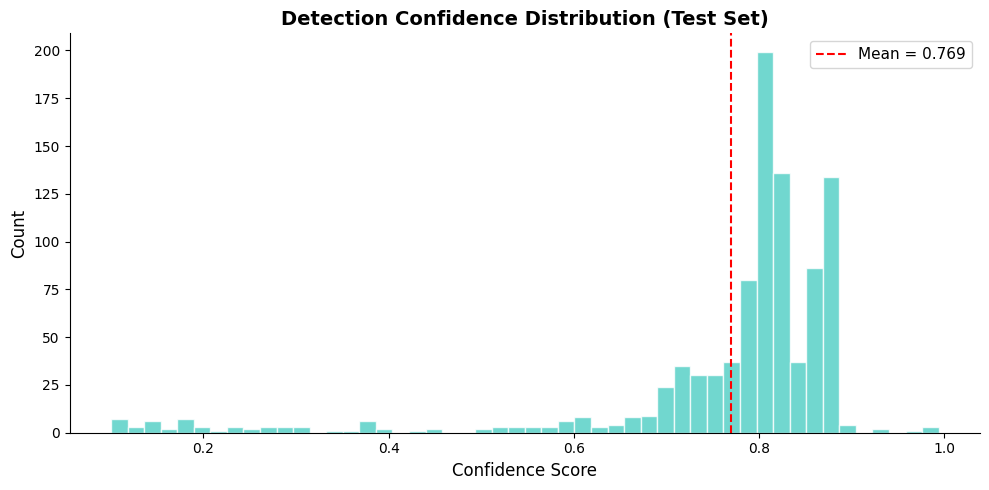

📊 Total detections: 946
   Mean confidence: 0.769
   Detections > 0.5: 889 (94.0%)
   Detections > 0.7: 824 (87.1%)


In [34]:
# ============================
# 8.2 Confidence score distribution
# ============================

all_confs = []
all_test_imgs = sorted(glob.glob(str(FILTERED_DIR / "test" / "images" / "*")))

for img_path in all_test_imgs:
    results = best_model.predict(source=img_path, conf=0.1, iou=0.45,
                                 imgsz=640, device=0, verbose=False)
    if len(results[0].boxes) > 0:
        confs = results[0].boxes.conf.cpu().numpy()
        all_confs.extend(confs.tolist())

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(all_confs, bins=50, color='#4ECDC4', edgecolor='white', alpha=0.8)
ax.set_xlabel('Confidence Score', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Detection Confidence Distribution (Test Set)', fontsize=14, fontweight='bold')
ax.axvline(np.mean(all_confs), color='red', linestyle='--',
           label=f'Mean = {np.mean(all_confs):.3f}')
ax.legend(fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

print(f"📊 Total detections: {len(all_confs)}")
print(f"   Mean confidence: {np.mean(all_confs):.3f}")
print(f"   Detections > 0.5: {sum(1 for c in all_confs if c > 0.5)} ({sum(1 for c in all_confs if c > 0.5)/len(all_confs)*100:.1f}%)")
print(f"   Detections > 0.7: {sum(1 for c in all_confs if c > 0.7)} ({sum(1 for c in all_confs if c > 0.7)/len(all_confs)*100:.1f}%)")

---
## 9. 📤 Export Model

Export model sang các format khác nhau cho real-time inference:
- **PyTorch (.pt)**: Dùng trực tiếp với ultralytics
- **ONNX (.onnx)**: Tối ưu cho CPU inference, cross-platform
- **TorchScript (.torchscript)**: Dùng với C++/LibTorch

In [35]:
# ============================
# 9.1 Export ONNX (khuyến nghị cho real-time)
# ============================

print("📦 Exporting to ONNX...")
onnx_path = best_model.export(
    format='onnx',
    imgsz=640,
    half=False,         # FP32 cho compatibility tốt hơn
    simplify=True,      # Simplify ONNX graph
    opset=12,
    dynamic=False,
)
print(f"✅ ONNX exported to: {onnx_path}")

# File size
import os
onnx_size = os.path.getsize(onnx_path) / (1024 * 1024)
pt_size = os.path.getsize(str(BEST_MODEL_PATH)) / (1024 * 1024)
print(f"\n📏 Model sizes:")
print(f"   PyTorch (.pt)  : {pt_size:.2f} MB")
print(f"   ONNX (.onnx)   : {onnx_size:.2f} MB")

📦 Exporting to ONNX...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/content/license_plate_yolov8n/train_v1/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 386ms
Prepared 4 packages in 1.89s
Installed 4 packages in 383ms
 + colorama==0.4.6
 + onnx==1.22.0
 + onnxruntime==1.28.0
 + onnxslim==0.1.95

requirements: AutoUpdate success ✅ 3.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export w

In [36]:
# ============================
# 9.2 Download models
# ============================

from google.colab import files

print("📥 Downloading best.pt...")
files.download(str(BEST_MODEL_PATH))

print("📥 Downloading ONNX model...")
files.download(str(onnx_path))

📥 Downloading best.pt...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Downloading ONNX model...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 10. 🎥 Real-time Webcam Script

Sau khi download `best.pt`, dùng script này chạy trên local machine với webcam:

In [37]:
realtime_script = '''
# ============================================
# realtime_lp_detect.py
# License Plate Detection — Real-time Webcam
# ============================================
# Usage: python realtime_lp_detect.py --weights best.pt

import cv2
import time
import argparse
from ultralytics import YOLO

def main():
    parser = argparse.ArgumentParser(description="Real-time License Plate Detection")
    parser.add_argument("--weights", type=str, default="best.pt", help="Path to YOLOv8 weights")
    parser.add_argument("--source", type=int, default=0, help="Webcam index (0, 1, ...)")
    parser.add_argument("--conf", type=float, default=0.35, help="Confidence threshold")
    parser.add_argument("--iou", type=float, default=0.45, help="NMS IoU threshold")
    parser.add_argument("--imgsz", type=int, default=640, help="Inference image size")
    args = parser.parse_args()

    # Load model
    model = YOLO(args.weights)
    print(f"✅ Model loaded: {args.weights}")

    # Open webcam
    cap = cv2.VideoCapture(args.source)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

    if not cap.isOpened():
        print("❌ Cannot open webcam!")
        return

    print("🎥 Press 'q' to quit")

    fps_counter = 0
    fps_start = time.time()
    fps_display = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Inference
        results = model.predict(
            source=frame,
            conf=args.conf,
            iou=args.iou,
            imgsz=args.imgsz,
            device=0,       # GPU. Đổi thành 'cpu' nếu không có GPU
            verbose=False,
            half=True,      # FP16 cho tốc độ nhanh hơn trên GPU
        )

        # Draw results
        annotated = results[0].plot(conf=True, line_width=2)

        # FPS calculation
        fps_counter += 1
        elapsed = time.time() - fps_start
        if elapsed >= 1.0:
            fps_display = fps_counter / elapsed
            fps_counter = 0
            fps_start = time.time()

        # Draw FPS
        cv2.putText(annotated, f"FPS: {fps_display:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

        # Draw detection count
        n_det = len(results[0].boxes)
        cv2.putText(annotated, f"Plates: {n_det}", (10, 65),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)

        cv2.imshow("License Plate Detection - YOLOv8n", annotated)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()
    print("👋 Done!")

if __name__ == "__main__":
    main()
'''

# Save script
with open('/content/realtime_lp_detect.py', 'w') as f:
    f.write(realtime_script)

print("✅ Real-time script saved to: /content/realtime_lp_detect.py")
print("\n📋 Cách sử dụng trên local:")
print("   1. Download best.pt và realtime_lp_detect.py")
print("   2. pip install ultralytics opencv-python")
print("   3. python realtime_lp_detect.py --weights best.pt")
print("   4. Nhấn 'q' để thoát")

✅ Real-time script saved to: /content/realtime_lp_detect.py

📋 Cách sử dụng trên local:
   1. Download best.pt và realtime_lp_detect.py
   2. pip install ultralytics opencv-python
   3. python realtime_lp_detect.py --weights best.pt
   4. Nhấn 'q' để thoát


In [38]:
# Download real-time script
files.download('/content/realtime_lp_detect.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 📋 Summary

| Metric | Value |
|--------|-------|
| Model | YOLOv8n (Nano) |
| Task | License Plate Detection (1 class) |
| Dataset | ~8,881 images (Roboflow) |
| Image Size | 640×640 |
| Export Formats | PyTorch (.pt), ONNX (.onnx) |

### Files được tạo ra:
- `best.pt` — Model tốt nhất (dùng cho inference)
- `best.onnx` — Model ONNX (tối ưu cho deployment)
- `realtime_lp_detect.py` — Script chạy webcam real-time

### Tips tăng FPS real-time:
1. Dùng `half=True` (FP16) khi chạy trên GPU
2. Giảm `imgsz` xuống 416 hoặc 320 nếu cần FPS cao hơn
3. Dùng ONNX Runtime thay vì PyTorch cho CPU inference
4. Tăng `conf` threshold để giảm postprocessing